# Data Visualization Learning Practice
### Data Analysis & Data Handling | Notebook 03

**Libraries:** Matplotlib, Seaborn, Pandas, NumPy  


## 1. Prepare the Dataset

### Create a small dataset for visualization practice.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="deep")

rng = np.random.default_rng(42)
months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

sales = pd.DataFrame({
    "month": months,
    "revenue": [12000, 13500, 12800, 15000, 16200, 15800, 17400, 18100, 16900, 19500, 21800, 24500],
    "orders": [120, 132, 125, 145, 151, 149, 162, 171, 160, 183, 201, 225],
    "marketing_spend": [1800, 1900, 1850, 2100, 2300, 2250, 2400, 2550, 2350, 2750, 3100, 3500],
    "customer_satisfaction": [3.8, 3.9, 3.7, 4.0, 4.1, 4.0, 4.2, 4.3, 4.1, 4.4, 4.5, 4.6]
})

products = pd.DataFrame({
    "category": ["Electronics", "Home", "Books", "Clothing", "Beauty"],
    "revenue": [42000, 28000, 15000, 32000, 21000],
    "units_sold": [210, 350, 500, 400, 300],
    "customer_rating": [4.4, 4.1, 4.6, 4.0, 4.3]
})

customer_data = pd.DataFrame({
    "age": rng.normal(34, 9, 120).clip(18, 65).round(),
    "monthly_spend": (rng.normal(180, 45, 120).clip(40, 350)).round(2),
    "visits_per_month": rng.integers(1, 16, 120),
    "segment": rng.choice(["Standard", "Silver", "Gold"], 120, p=[0.55, 0.30, 0.15])
})

sales.head()

,month,revenue,orders,marketing_spend,customer_satisfaction
0,Jan,12000,120,1800,3.8
1,Feb,13500,132,1900,3.9
2,Mar,12800,125,1850,3.7
3,Apr,15000,145,2100,4.0
4,May,16200,151,2300,4.1


## 2. Matplotlib Fundamentals

### Create a basic Matplotlib figure and axes.

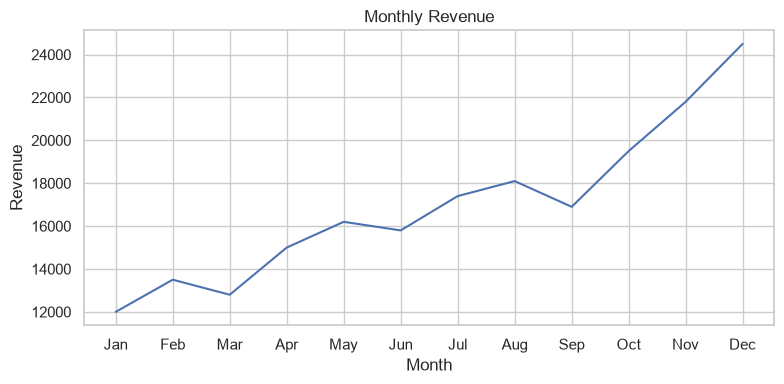

In [2]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(sales["month"], sales["revenue"])
ax.set_title("Monthly Revenue")
ax.set_xlabel("Month")
ax.set_ylabel("Revenue")
plt.tight_layout()
plt.show()

### Customize a chart with a title, axis labels, markers, grid, and legend.

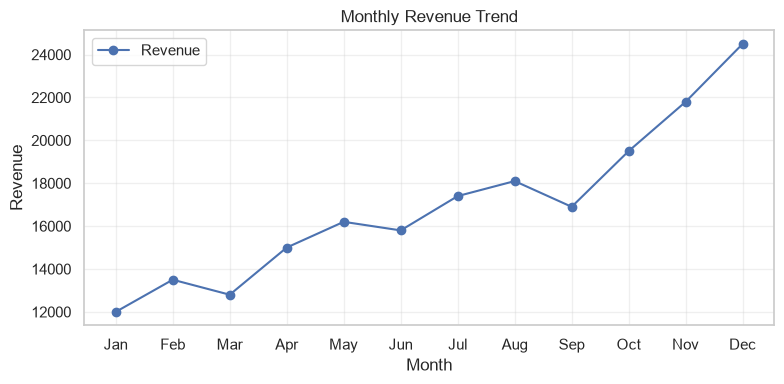

In [3]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(sales["month"], sales["revenue"], marker="o", label="Revenue")
ax.set(title="Monthly Revenue Trend", xlabel="Month", ylabel="Revenue")
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

### Create two charts in one figure using subplots.

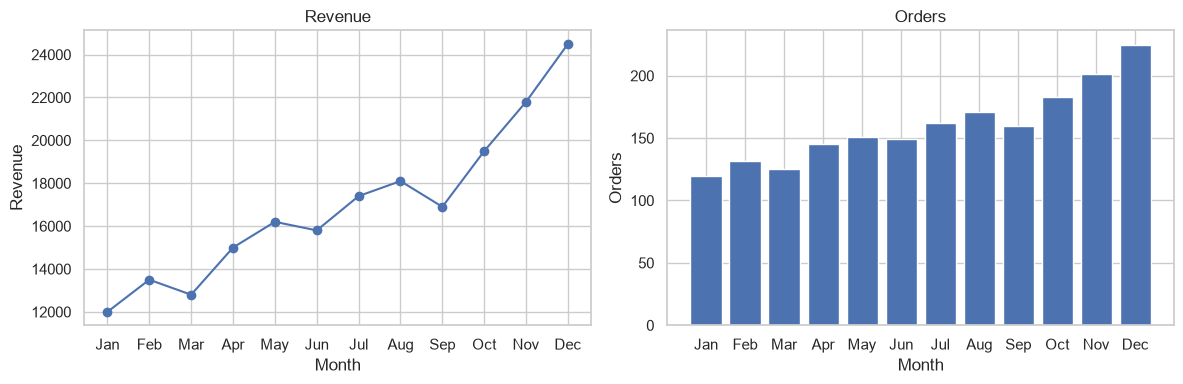

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(sales["month"], sales["revenue"], marker="o")
axes[0].set(title="Revenue", xlabel="Month", ylabel="Revenue")
axes[1].bar(sales["month"], sales["orders"])
axes[1].set(title="Orders", xlabel="Month", ylabel="Orders")
plt.tight_layout()
plt.show()

## 3. Seaborn Fundamentals

### Create a Seaborn scatter plot with a fitted trend line.

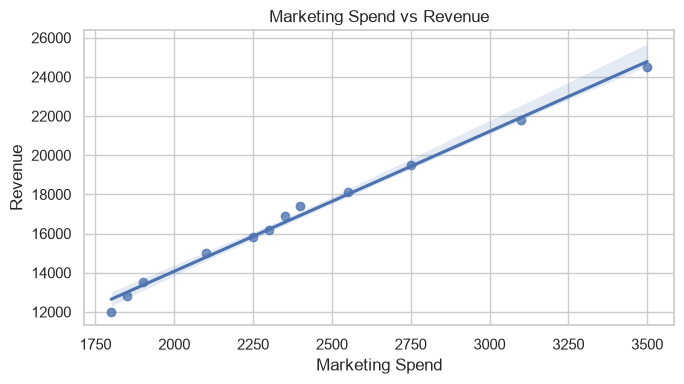

In [5]:
plt.figure(figsize=(7, 4))
sns.regplot(data=sales, x="marketing_spend", y="revenue")
plt.title("Marketing Spend vs Revenue")
plt.xlabel("Marketing Spend")
plt.ylabel("Revenue")
plt.tight_layout()
plt.show()

### Compare a numerical variable across customer segments.

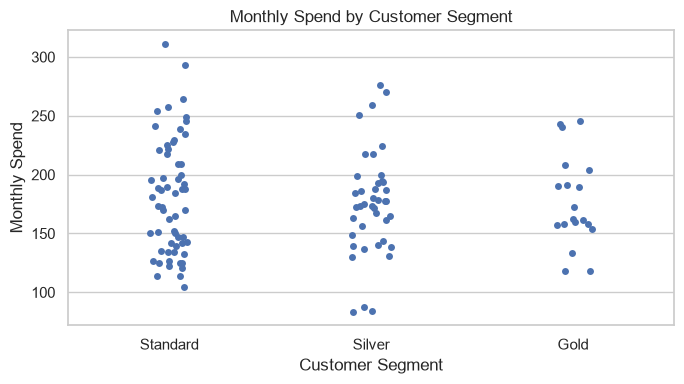

In [6]:
plt.figure(figsize=(7, 4))
sns.stripplot(data=customer_data, x="segment", y="monthly_spend", jitter=True)
plt.title("Monthly Spend by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Monthly Spend")
plt.tight_layout()
plt.show()

## 4. Line, Bar, and Scatter Plots

### Visualize monthly revenue as a line plot.

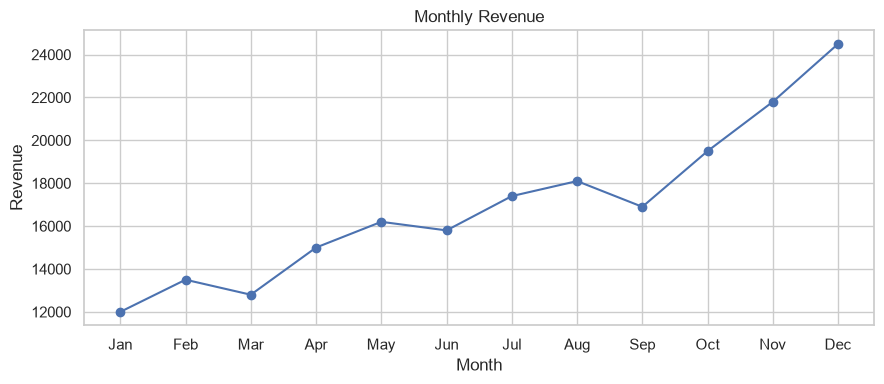

In [7]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(sales["month"], sales["revenue"], marker="o")
ax.set(title="Monthly Revenue", xlabel="Month", ylabel="Revenue")
plt.tight_layout()
plt.show()

### Compare revenue by product category using a bar plot.

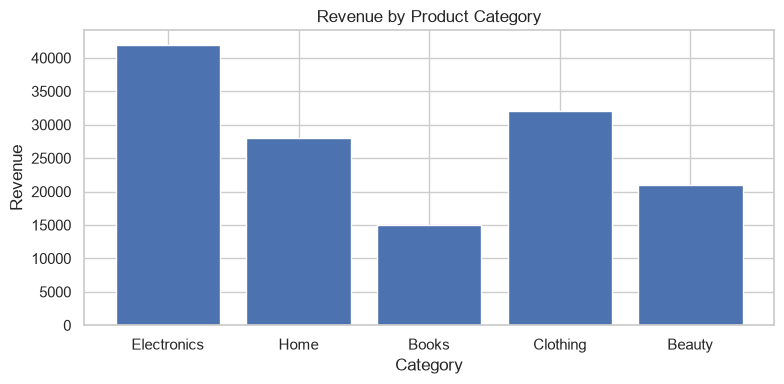

In [8]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(products["category"], products["revenue"])
ax.set(title="Revenue by Product Category", xlabel="Category", ylabel="Revenue")
plt.tight_layout()
plt.show()

### Explore the relationship between marketing spend and revenue using a scatter plot.

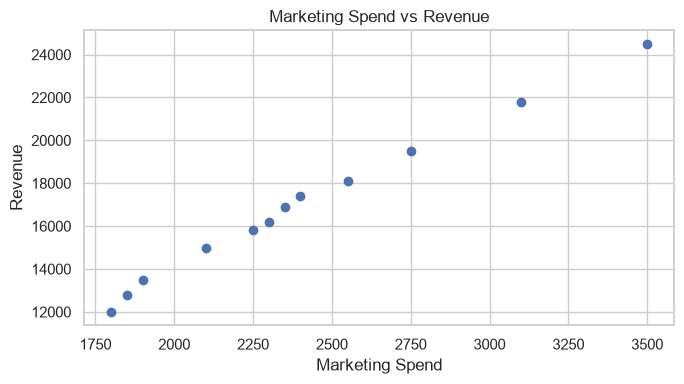

In [9]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(sales["marketing_spend"], sales["revenue"])
ax.set(title="Marketing Spend vs Revenue", xlabel="Marketing Spend", ylabel="Revenue")
plt.tight_layout()
plt.show()

## 5. Histograms and Distribution Plots

### Visualize the distribution of customer monthly spend with a histogram.

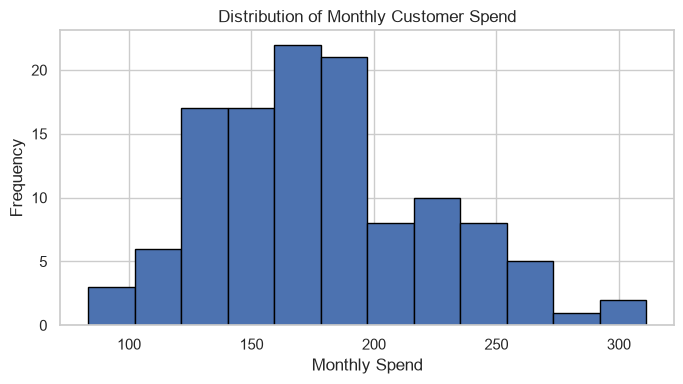

In [10]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(customer_data["monthly_spend"], bins=12, edgecolor="black")
ax.set(title="Distribution of Monthly Customer Spend", xlabel="Monthly Spend", ylabel="Frequency")
plt.tight_layout()
plt.show()

### Visualize the distribution with a Seaborn histogram and density curve.

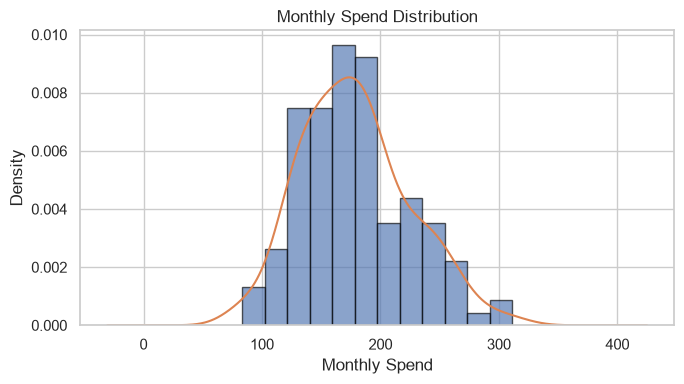

In [11]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(customer_data["monthly_spend"], bins=12, density=True, edgecolor="black", alpha=0.65)
customer_data["monthly_spend"].plot(kind="kde", ax=ax)
ax.set(title="Monthly Spend Distribution", xlabel="Monthly Spend", ylabel="Density")
plt.tight_layout()
plt.show()

## 6. Box Plots

### Compare monthly spend distributions across customer segments using a box plot.

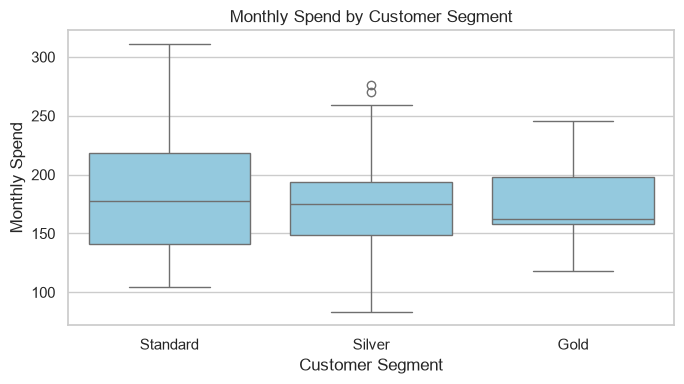

In [12]:
plt.figure(figsize=(7, 4))
sns.boxplot(data=customer_data, x="segment", y="monthly_spend", color="skyblue")
plt.title("Monthly Spend by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Monthly Spend")
plt.tight_layout()
plt.show()

### Compare revenue and marketing spend after standardizing their scales.

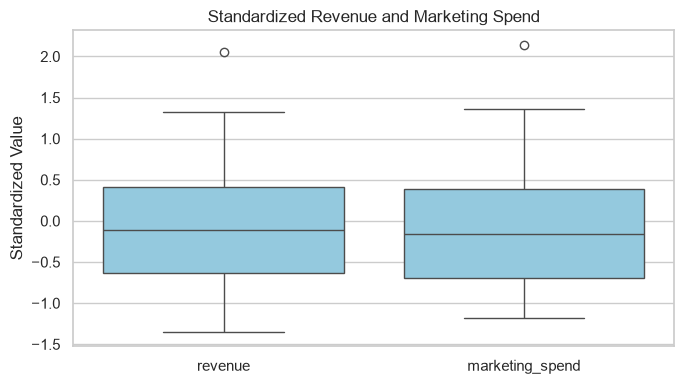

In [13]:
scaled_metrics = sales[["revenue", "marketing_spend"]].apply(lambda col: (col - col.mean()) / col.std())
plt.figure(figsize=(7, 4))
sns.boxplot(data=scaled_metrics, color="skyblue")
plt.title("Standardized Revenue and Marketing Spend")
plt.ylabel("Standardized Value")
plt.tight_layout()
plt.show()

## 7. Heatmaps

### Create a heatmap of monthly business metrics.

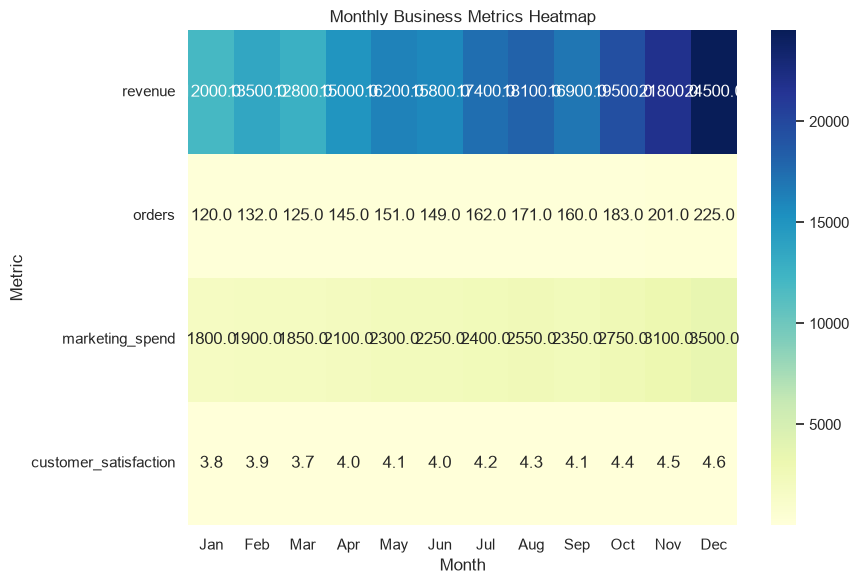

In [14]:
heatmap_data = sales.set_index("month")[["revenue", "orders", "marketing_spend", "customer_satisfaction"]]
plt.figure(figsize=(9, 6))
sns.heatmap(heatmap_data.T, annot=True, fmt=".1f", cmap="YlGnBu")
plt.title("Monthly Business Metrics Heatmap")
plt.xlabel("Month")
plt.ylabel("Metric")
plt.tight_layout()
plt.show()

### Create a pivot table and visualize category revenue by a simple sales tier.

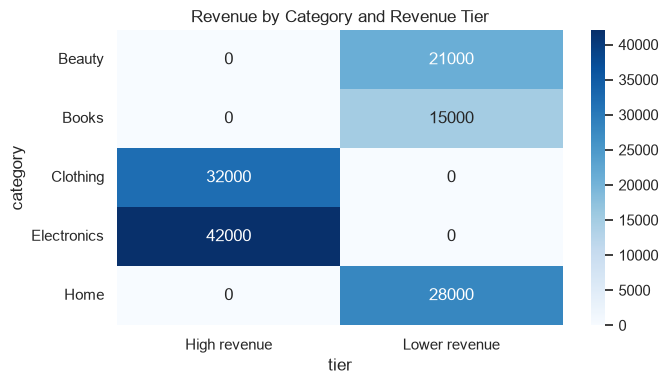

In [15]:
category_tier = products.assign(
    tier=np.where(products["revenue"] >= 30000, "High revenue", "Lower revenue")
).pivot_table(index="category", columns="tier", values="revenue", aggfunc="sum", fill_value=0)
plt.figure(figsize=(7, 4))
sns.heatmap(category_tier, annot=True, fmt=".0f", cmap="Blues")
plt.title("Revenue by Category and Revenue Tier")
plt.tight_layout()
plt.show()

## 8. Correlation Visualization

### Calculate correlations between numeric customer metrics.

In [16]:
customer_data[["age", "monthly_spend", "visits_per_month"]].corr()

,age,monthly_spend,visits_per_month
age,1.000000,-0.125946,-0.047024
monthly_spend,-0.125946,1.000000,0.042735
visits_per_month,-0.047024,0.042735,1.000000


### Visualize numeric correlations using a heatmap.

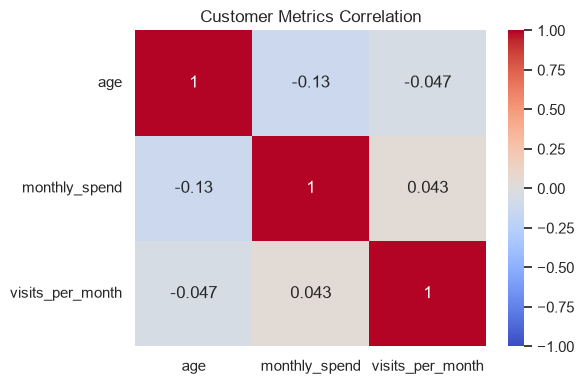

In [17]:
corr = customer_data[["age", "monthly_spend", "visits_per_month"]].corr()
plt.figure(figsize=(6, 4))
sns.heatmap(corr, annot=True, vmin=-1, vmax=1, center=0, cmap="coolwarm")
plt.title("Customer Metrics Correlation")
plt.tight_layout()
plt.show()

### Plot the relationship between age and monthly spend with a fitted line.

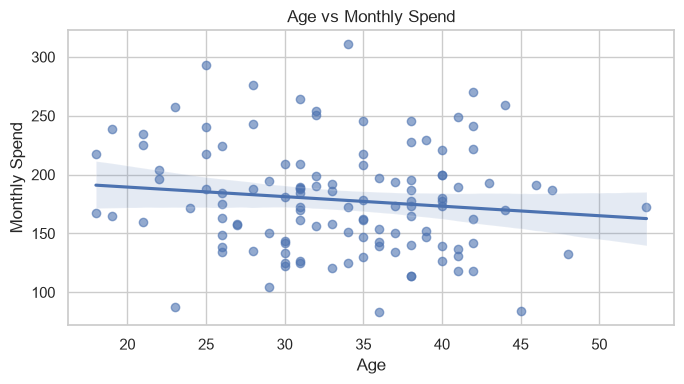

In [18]:
plt.figure(figsize=(7, 4))
sns.regplot(data=customer_data, x="age", y="monthly_spend", scatter_kws={"alpha": 0.6})
plt.title("Age vs Monthly Spend")
plt.xlabel("Age")
plt.ylabel("Monthly Spend")
plt.tight_layout()
plt.show()

## 9. Chart Labeling and Interpretation

### Add clear labels, units, and a note to a revenue chart.

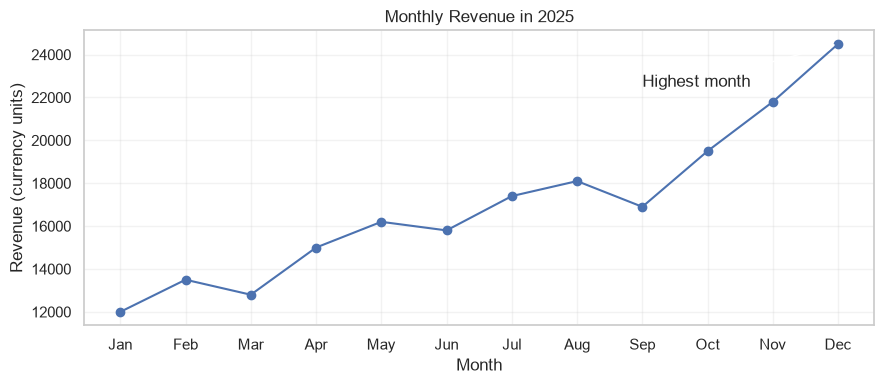

In [19]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(sales["month"], sales["revenue"], marker="o")
ax.set_title("Monthly Revenue in 2025")
ax.set_xlabel("Month")
ax.set_ylabel("Revenue (currency units)")
ax.annotate("Highest month", xy=("Dec", 24500), xytext=("Sep", 22500),
            arrowprops={"arrowstyle": "->"})
ax.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()

### Calculate summary values to support interpretation of the revenue chart.

In [20]:
pd.Series({
    "highest_revenue_month": sales.loc[sales["revenue"].idxmax(), "month"],
    "highest_month_revenue": sales["revenue"].max(),
    "lowest_revenue_month": sales.loc[sales["revenue"].idxmin(), "month"],
    "lowest_month_revenue": sales["revenue"].min(),
    "revenue_change_first_to_last": sales["revenue"].iloc[-1] - sales["revenue"].iloc[0]
})

highest_revenue_month             Dec
highest_month_revenue           24500
lowest_revenue_month              Jan
lowest_month_revenue            12000
revenue_change_first_to_last    12500
dtype: object

## 10. Choosing the Right Chart

### Compare category values when the goal is ranking.

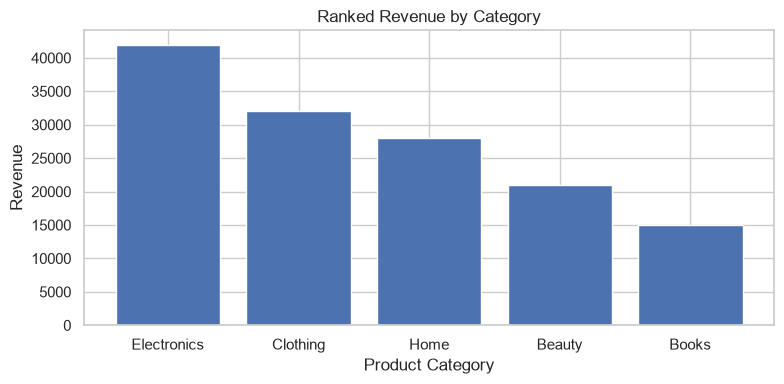

In [21]:
fig, ax = plt.subplots(figsize=(8, 4))
ranked_products = products.sort_values("revenue", ascending=False)
ax.bar(ranked_products["category"], ranked_products["revenue"])
ax.set(title="Ranked Revenue by Category", xlabel="Product Category", ylabel="Revenue")
plt.tight_layout()
plt.show()

### Show a continuous trend over time.

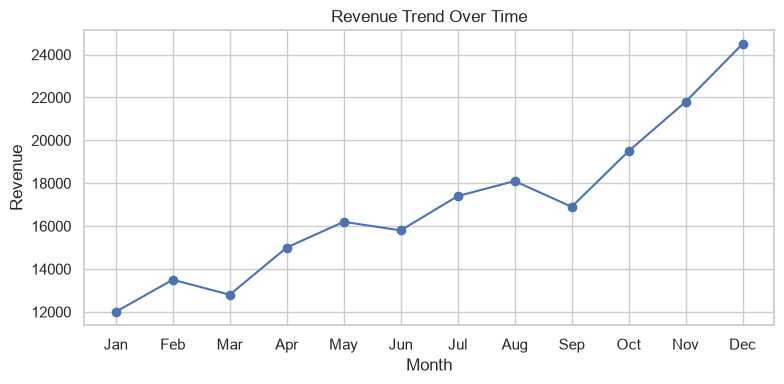

In [22]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(sales["month"], sales["revenue"], marker="o")
ax.set(title="Revenue Trend Over Time", xlabel="Month", ylabel="Revenue")
plt.tight_layout()
plt.show()

### Explore the relationship between two numerical variables.

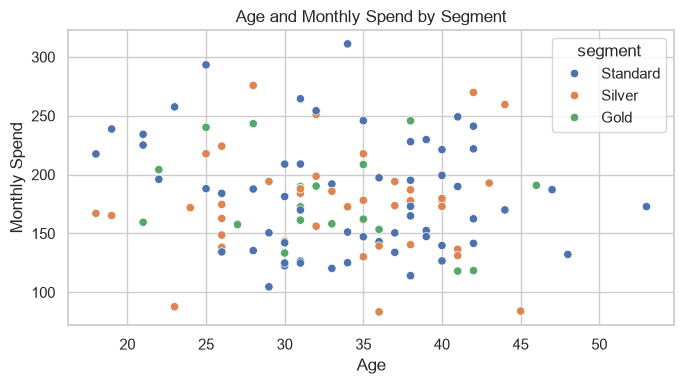

In [23]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.scatterplot(data=customer_data, x="age", y="monthly_spend", hue="segment")
ax.set(title="Age and Monthly Spend by Segment", xlabel="Age", ylabel="Monthly Spend")
plt.tight_layout()
plt.show()

### Compare a numerical distribution and potential outliers.

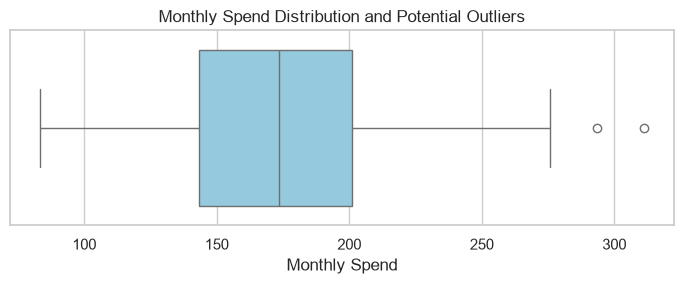

In [24]:
fig, ax = plt.subplots(figsize=(7, 3))
sns.boxplot(x=customer_data["monthly_spend"], ax=ax, color="skyblue")
ax.set(title="Monthly Spend Distribution and Potential Outliers", xlabel="Monthly Spend")
plt.tight_layout()
plt.show()

### Summarize chart choice by analytical goal.

In [25]:
pd.DataFrame({
    "Analytical goal": ["Trend over time", "Compare categories", "Relationship", "Distribution", "Outliers", "Correlation matrix"],
    "Recommended chart": ["Line plot", "Bar plot", "Scatter plot", "Histogram / KDE", "Box plot", "Correlation heatmap"]
})

,Analytical goal,Recommended chart
0,Trend over time,Line plot
1,Compare categories,Bar plot
2,Relationship,Scatter plot
3,Distribution,Histogram / KDE
4,Outliers,Box plot
5,Correlation matrix,Correlation heatmap
